# 01 — Data preparation

This notebook prepares the data for the football prediction project.

1. **Collect** English Premier League matches from Understat (via `soccerdata`), cached in `data/raw/`.
2. **Clean** them: types, dates, duplicates, team names, missing values, chronological order.
3. **Engineer pre-match features** such as rolling xG and recent form.
4. **Fit the historical baseline**, the benchmark every later model must beat.
5. **Save** the result to `data/processed/processed_matches.csv`.

**The leakage rule.** A prediction for a match on day *D* may only use matches played *strictly before* day *D*.
So a match's rolling xG never includes its own xG, and nothing from later matches is used.
The functions in `src/features.py` enforce this, and `tests/test_leakage.py` checks it.

In [49]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (LEAGUE, SEASONS, clean_matches, download_understat_matches,
                      load_processed, save_processed)
from src.features import (FEATURE_COLUMNS, build_fixture_features, build_match_features,
                          drop_incomplete)
from src.models import HistoricalBaseline

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", PROJECT_ROOT)

Project root: /Users/keanudiamante/Documents/College/DataWise/Machine Learning/fml-footballpredictor 2


## 0. Run the tests first

If anything fails here, fix it before trusting any output below.

In [34]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

......................................                                   [100%]
38 passed in 0.27s



## 1. Data collection

The first run downloads from Understat and saves a CSV in `data/raw/`. Later runs read that file, with no internet needed.
Set `FORCE_DOWNLOAD = True` to refresh, for example to get the latest results of the current season.

In [35]:
FORCE_DOWNLOAD = False

raw = download_understat_matches(LEAGUE, SEASONS, force_download=FORCE_DOWNLOAD)
print(raw.shape)

Loading cached raw data: data/raw/understat_ENG-Premier-League_1617-2627.csv
(4180, 20)


### Inspect the raw data before relying on it

Check the column names and types that soccerdata actually returned.

In [36]:
print("Columns:", list(raw.columns))
print()
print(raw.dtypes)

Columns: ['league', 'season', 'game', 'league_id', 'season_id', 'game_id', 'date', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'away_team_code', 'home_team_code', 'home_goals', 'away_goals', 'home_xg', 'away_xg', 'is_result', 'has_data', 'url']

league                str
season              int64
game                  str
league_id           int64
season_id           int64
game_id             int64
date                  str
home_team_id        int64
away_team_id        int64
home_team             str
away_team             str
away_team_code        str
home_team_code        str
home_goals        float64
away_goals        float64
home_xg           float64
away_xg           float64
is_result            bool
has_data             bool
url                   str
dtype: object


In [37]:
raw.head()

,league,season,game,league_id,season_id,game_id,date,home_team_id,away_team_id,home_team,away_team,away_team_code,home_team_code,home_goals,away_goals,home_xg,away_xg,is_result,has_data,url
0,ENG-Premier League,1617,2016-08-13 Burnley-Swansea,1,2016,464,2016-08-13 18:00:00,92,84,Burnley,Swansea,SWA,BUR,0.0,1.0,1.049030,1.720890,True,True,https://understat.com/match/464
1,ENG-Premier League,1617,2016-08-13 Crystal Palace-West Bromwich Albion,1,2016,462,2016-08-13 18:00:00,78,76,Crystal Palace,West Bromwich Albion,WBA,CRY,0.0,1.0,0.990062,0.684593,True,True,https://understat.com/match/462
2,ENG-Premier League,1617,2016-08-13 Everton-Tottenham,1,2016,463,2016-08-13 18:00:00,72,82,Everton,Tottenham,TOT,EVE,1.0,1.0,0.790063,1.123480,True,True,https://understat.com/match/463
3,ENG-Premier League,1617,2016-08-13 Hull-Leicester,1,2016,461,2016-08-13 15:30:00,91,75,Hull,Leicester,LEI,HUL,2.0,1.0,0.740018,2.456310,True,True,https://understat.com/match/461
4,ENG-Premier League,1617,2016-08-13 Manchester City-Sunderland,1,2016,467,2016-08-13 20:30:00,88,77,Manchester City,Sunderland,SUN,MCI,2.0,1.0,1.954790,1.098770,True,True,https://understat.com/match/467


In [38]:
print("Rows per season:")
print(raw["season"].value_counts().sort_index())
if "is_result" in raw.columns:
    print("\nPlayed (True) vs not yet played (False):")
    print(raw["is_result"].value_counts())
print("\nMissing values per column:")
print(raw.isna().sum())

Rows per season:
season
1617    380
1718    380
1819    380
1920    380
2021    380
2122    380
2223    380
2324    380
2425    380
2526    380
2627    380
Name: count, dtype: int64

Played (True) vs not yet played (False):
is_result
True     3860
False     320
Name: count, dtype: int64

Missing values per column:
league              0
season              0
game                0
league_id           0
season_id           0
game_id             0
date                0
home_team_id        0
away_team_id        0
home_team           0
away_team           0
away_team_code      0
home_team_code      0
home_goals        320
away_goals        320
home_xg           320
away_xg           320
is_result           0
has_data            0
url                 0
dtype: int64


## 2. Cleaning

In [39]:
matches = clean_matches(raw)
matches.head()

Cleaning report
  raw rows                              4180
  after removing unplayed fixtures      3860
  dropped (missing values)                 0
  dropped (invalid values)                 0
  dropped (duplicates)                     0
  clean rows                            3860


,date,home_team,away_team,home_goals,away_goals,home_xg,away_xg,season,game_id,result
0,2016-08-13 15:30:00,Hull,Leicester,2,1,0.740018,2.456310,1617,461,H
1,2016-08-13 18:00:00,Burnley,Swansea,0,1,1.049030,1.720890,1617,464,A
2,2016-08-13 18:00:00,Crystal Palace,West Bromwich Albion,0,1,0.990062,0.684593,1617,462,A
3,2016-08-13 18:00:00,Everton,Tottenham,1,1,0.790063,1.123480,1617,463,D
4,2016-08-13 18:00:00,Middlesbrough,Stoke,1,1,1.805230,0.485626,1617,465,D


### Sanity checks

A complete Premier League season has **380 matches and 20 teams**. The current season will have fewer matches so far.

In [40]:
summary = matches.groupby("season").agg(
    matches=("date", "size"),
    teams=("home_team", "nunique"),
    first_match=("date", "min"),
    last_match=("date", "max"),
)
print(summary)
print("\nDates in chronological order:", matches["date"].is_monotonic_increasing)

        matches  teams         first_match          last_match
season                                                        
1617        380     20 2016-08-13 15:30:00 2017-05-21 15:00:00
1718        380     20 2017-08-11 19:45:00 2018-05-13 15:00:00
1819        380     20 2018-08-10 22:00:00 2019-05-12 14:00:00
1920        380     20 2019-08-09 20:00:00 2020-07-26 15:00:00
2021        380     20 2020-09-12 11:30:00 2021-05-23 15:00:00
2122        380     20 2021-08-13 19:00:00 2022-05-22 15:00:00
2223        380     20 2022-08-05 19:00:00 2023-05-28 15:30:00
2324        380     20 2023-08-11 19:00:00 2024-05-19 15:00:00
2425        380     20 2024-08-16 19:00:00 2025-05-25 15:00:00
2526        380     20 2025-08-15 19:00:00 2026-05-24 15:00:00
2627         60     20 2026-08-21 19:00:00 2026-10-12 19:00:00

Dates in chronological order: True


Check the team list for the same club under two names. If you see one, add it to `TEAM_NAME_MAP` in `src/data.py`.

In [41]:
teams = sorted(set(matches["home_team"]) | set(matches["away_team"]))
print(len(teams), "teams:")
print(teams)

35 teams:
['Arsenal', 'Aston Villa', 'Bournemouth', 'Brentford', 'Brighton', 'Burnley', 'Cardiff', 'Chelsea', 'Coventry', 'Crystal Palace', 'Everton', 'Fulham', 'Huddersfield', 'Hull', 'Ipswich', 'Leeds', 'Leicester', 'Liverpool', 'Luton', 'Manchester City', 'Manchester United', 'Middlesbrough', 'Newcastle United', 'Norwich', 'Nottingham Forest', 'Sheffield United', 'Southampton', 'Stoke', 'Sunderland', 'Swansea', 'Tottenham', 'Watford', 'West Bromwich Albion', 'West Ham', 'Wolverhampton Wanderers']


In [42]:
print("Overall outcome shares (H = home win, D = draw, A = away win):")
print(matches["result"].value_counts(normalize=True).reindex(["H", "D", "A"]).round(3))
print()
print("Average per match:")
print(matches[["home_goals", "away_goals", "home_xg", "away_xg"]].mean().round(2))

Overall outcome shares (H = home win, D = draw, A = away win):
result
H    0.445
D    0.234
A    0.321
Name: proportion, dtype: float64

Average per match:
home_goals    1.56
away_goals    1.28
home_xg       1.61
away_xg       1.31
dtype: float64


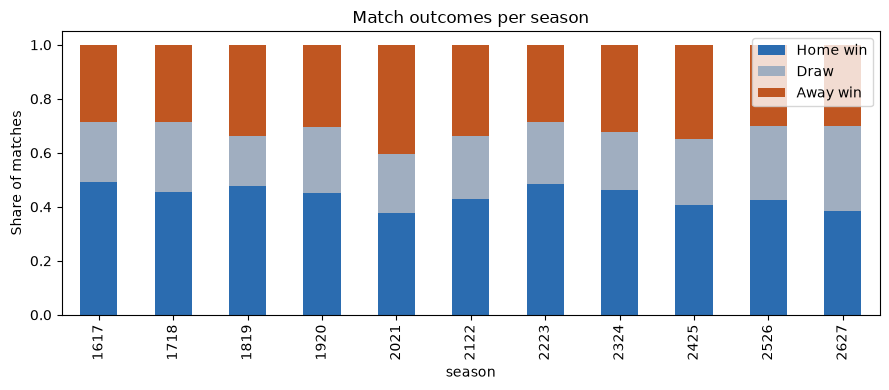

In [43]:
by_season = (matches.groupby("season")["result"].value_counts(normalize=True)
             .unstack().reindex(columns=["H", "D", "A"]))
ax = by_season.plot(kind="bar", stacked=True, figsize=(9, 4), color=["#2b6cb0", "#a0aec0", "#c05621"])
ax.set_ylabel("Share of matches")
ax.set_title("Match outcomes per season")
ax.legend(["Home win", "Draw", "Away win"], loc="upper right")
plt.tight_layout()
plt.show()

## 3. Feature engineering

For every match, each team gets features from **its own previous matches only**:

| Feature | Meaning |
|---|---|
| `roll_xg_for` | average xG created in the last 5 matches |
| `roll_xg_against` | average xG conceded (xGA) in the last 5 matches |
| `roll_goals_for` / `roll_goals_against` | average goals scored / conceded in the last 5 matches |
| `roll_points` | points from the last 5 matches (0–15) |
| `roll_win_rate` | share of the last 5 matches won |
| `venue_ppg` | points per game in the last 5 home matches (home team) or away matches (away team) |
| `venue_xgd` | xG minus xGA per game in those same venue matches |

Each appears as `home_...` and `away_...`, plus home-minus-away differences such as `xg_for_diff`.

Windows run across season boundaries, so early-season matches use the end of last season.
A team needs **5 earlier matches** (and at least 3 at the venue) before it gets features.
Before that the features are empty and the match is left out of modelling. This mainly affects
the first weeks of the data and newly promoted teams.

In [44]:
features = build_match_features(matches)
print(features.shape)
features[["date", "home_team", "away_team", "result"] + FEATURE_COLUMNS[:4]].tail()

(3860, 34)


,date,home_team,away_team,result,home_roll_xg_for,home_roll_xg_against,home_roll_goals_for,home_roll_goals_against
3855,2026-10-10 16:30:00,Manchester United,Tottenham,D,2.117004,1.443192,1.6,1.6
3856,2026-10-11 13:00:00,Crystal Palace,Nottingham Forest,H,1.516864,2.003992,1.2,2.2
3857,2026-10-11 13:00:00,Hull,Everton,D,1.146178,1.437056,1.2,0.8
3858,2026-10-11 15:30:00,Liverpool,Manchester City,A,1.648832,1.387830,1.4,0.8
3859,2026-10-12 19:00:00,Coventry,Newcastle United,H,0.995119,1.717609,0.2,2.0


In [45]:
complete = drop_incomplete(features)
dropped = features.loc[features[FEATURE_COLUMNS].isna().any(axis=1)]
print(f"Matches with all features: {len(complete)} of {len(features)}")
print(f"Left out (not enough history): {len(dropped)}")
print()
print("Left-out matches per season:")
print(dropped["season"].value_counts().sort_index())

Matches with all features: 3710 of 3860
Left out (not enough history): 150

Left-out matches per season:
season
1617    62
1718    16
1819    18
1920    18
2021     6
2122     6
2223     6
2324     6
2425     6
2627     6
Name: count, dtype: int64


### Leakage spot check

Rebuild the features for one historical match with the separate one-fixture function, which only
sees matches before that date. The two methods should agree. The full check is in `tests/test_leakage.py`.

In [46]:
example = complete.iloc[-1]
single = build_fixture_features(matches, example["home_team"], example["away_team"], example["date"])
diff = (single[FEATURE_COLUMNS].iloc[0].astype(float) - example[FEATURE_COLUMNS].astype(float)).abs().max()

print(f"{example['home_team']} vs {example['away_team']} on {example['date'].date()}")
print(f"Largest difference between the two methods: {diff:.2e}")
single[FEATURE_COLUMNS].T.rename(columns={0: "value"}).round(3)

Liverpool vs Manchester City on 2026-10-11
Largest difference between the two methods: 6.66e-16


,value
home_roll_xg_for,1.649
home_roll_xg_against,1.388
home_roll_goals_for,1.400
home_roll_goals_against,0.800
home_roll_points,9.000
home_roll_win_rate,0.400
home_venue_ppg,1.400
home_venue_xgd,0.017
away_roll_xg_for,2.208
away_roll_xg_against,1.435


## 4. Historical baseline

The baseline predicts the same probabilities for every match: the share of home wins, draws and
away wins in past matches. Fitted here on everything **before the 2025/26 season**. The 2025/26
frequencies are shown for comparison only; proper evaluation (log loss, Brier, RPS) comes in Stage 3.

In [47]:
SPLIT_DATE = pd.Timestamp("2025-07-01")

train = complete[complete["date"] < SPLIT_DATE]
holdout = complete[(complete["date"] >= SPLIT_DATE) & (complete["date"] < "2026-07-01")]

baseline = HistoricalBaseline().fit(train["result"])
comparison = pd.DataFrame({
    "baseline probability (pre-2025/26)": baseline.probabilities_,
    "actual share in 2025/26": holdout["result"].value_counts(normalize=True).reindex(["H", "D", "A"]).to_numpy(),
}, index=["Home win", "Draw", "Away win"]).round(3)

print(f"Baseline fitted on {baseline.n_matches_} matches; 2025/26 has {len(holdout)} matches.")
comparison

Baseline fitted on 3276 matches; 2025/26 has 380 matches.


,baseline probability (pre-2025/26),actual share in 2025/26
Home win,0.449,0.426
Draw,0.227,0.274
Away win,0.324,0.300


## 5. Save

All cleaned matches with their features are saved, including the ones with empty features, so nothing is lost.
Notebook 02 drops the incomplete rows before training.

In [48]:
path = save_processed(features)
check = load_processed(path)
print(f"Saved {len(check)} rows and {check.shape[1]} columns to {path.relative_to(PROJECT_ROOT)}")
print("Date range:", check["date"].min().date(), "to", check["date"].max().date())

Saved 3860 rows and 34 columns to data/processed/processed_matches.csv
Date range: 2016-08-13 to 2026-10-12
